In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import simple_norm
from astropy.modeling.models import Sersic2D
from astropy.convolution import convolve, Gaussian2DKernel
from astropy.stats import sigma_clipped_stats, SigmaClip
from astropy.visualization import simple_norm
from photutils.segmentation import detect_threshold, detect_sources, SourceCatalog
import statmorph
from statmorph.utils.image_diagnostics import make_figure
%matplotlib inline

from astropy.io import fits
from photutils.background import Background2D, MedianBackground

from astropy.cosmology import Planck18 as cosmo
from astropy import units as u

from skimage import measure
from skimage import io, color
import skimage.morphology as morph
from skimage.measure import label
from skimage.filters import threshold_otsu

from IPython.display import display

In [2]:
def reorder_fits(fits_filename, selected_image_index, exstr=''):
    # Step 1: Open the original FITS file
    with fits.open(fits_filename) as hdul:
        # Step 2: Extract the 3D data stack from hdul.data
        data = hdul[0].data  # Assuming the image stack is in the primary HDU
        
        # Step 3: Ensure the selected image index is within range
        if selected_image_index < 0 or selected_image_index >= data.shape[0]:
            raise IndexError("Selected image index is out of range")

        # Step 4: Rearrange the 3D stack to bring the selected image to the front
        selected_image = data[selected_image_index]
        data = np.delete(data, selected_image_index, axis=0)
        data = np.insert(data, 0, selected_image, axis=0)

        # Step 5: Create a new HDU with the modified data
        new_hdu = fits.PrimaryHDU(data)
        new_hdul = fits.HDUList([new_hdu] + hdul[1:])

        # Step 6: Write the new FITS file
        new_hdul.writeto(f"fits/temp/{exstr}tempfits.fits", overwrite=True)
        new_hdul.close()
    

def paramFinder(wavet=0, fits_filename=f"fits/temp/tempfits.fits", verb=False):
    with fits.open(fits_filename) as hdul:
        if verb:
            print(hdul.info())
            print('----------------------------')
            print(hdul[0].header)
            print(hdul[1].header)
            print('----------------------------')
        dims = list(np.shape(hdul[0].data[wavet]))
        #print(np.max(hdul[0].data))

        exp = hdul[0].header.get('EXPTIME', 1.0)
        gain = hdul[0].header.get('GAIN', 1.0)

        flux = (hdul[0].data[wavet].sum())*gain/exp
        if verb:
            print('Flux:',flux)

        #plt.figure()
        #plt.imshow(hdul[0].data[wavet])
        #for i in hdul:
        #    plt.figure()
        #    plt.imshow(hdul[i].data[wavet])
        #os.remove(f"fits/temp/{exstr}tempfits.fits")
        image = np.array(hdul[0].data[wavet])
        return image #[65:-50, 65:-50]

In [3]:
def subtract_background(image, box_size=50, filter_size=3, sigma=3.0, show=False):
    """
    Subtract background from a simulated galaxy image using Background2D.

    Parameters
    ----------
    image : 2D numpy.ndarray
        The input galaxy image.
    box_size : int or tuple of int, optional
        Size of the box to estimate the background.
    filter_size : int or tuple of int, optional
        Size of the filter to smooth the background map.
    sigma : float, optional
        Sigma level for sigma clipping.
    show : bool, optional
        If True, display the original, background, and subtracted images.

    Returns
    -------
    image_subtracted : 2D numpy.ndarray
        The background-subtracted image.
    background : 2D numpy.ndarray
        The estimated background.
    """
    sigma_clip = SigmaClip(sigma=sigma)
    bkg_estimator = MedianBackground()
    
    bkg = Background2D(image, box_size, filter_size=filter_size,
                       sigma_clip=sigma_clip, bkg_estimator=bkg_estimator)
    
    image_subtracted = image - bkg.background

    if show:
        norm = simple_norm(image, 'sqrt', percent=99)
        fig, axs = plt.subplots(1, 3, figsize=(15, 5))
        axs[0].imshow(image, origin='lower', norm=norm)
        axs[0].set_title('Original Image')
        axs[1].imshow(bkg.background, origin='lower', norm=norm)
        axs[1].set_title('Estimated Background')
        axs[2].imshow(image_subtracted, origin='lower', norm=norm)
        axs[2].set_title('Background Subtracted')
        for ax in axs:
            ax.axis('off')
        plt.tight_layout()
        plt.show()

    return image_subtracted, bkg.background

In [4]:
def makeSegmap(image):
    Thresh = threshold_otsu(image)
    picBW = image > Thresh
    
    Strel = morph.disk(2)
    BWimg_dil = morph.dilation(picBW,Strel)
    Strel2 = morph.disk(5)
    BWimg_close = morph.closing(BWimg_dil,Strel2)
    
    L = label(BWimg_close)
    half_length = int(np.floor(np.size(L,1)/2))
    L_cntr = L[half_length,half_length]
    Seg = L
    Seg[Seg != L_cntr] = 0
    Seg[Seg == L_cntr] = 1
    Mask = morph.dilation(Seg,Strel2)
    
    #plt.figure(figsize=(7,7))
    #io.imshow(L)
    #plt.show()
    
    return Mask

In [42]:
def runStatMorph(image):
    kernel = Gaussian2DKernel(1.5)
    kernel.normalize()  # make sure kernel adds up to 1
    psf = kernel.array  # we only need the numpy array
    image = convolve(image, psf)
    
    segmap = makeSegmap(image)
    
    #Threshold Segmentation
    #threshold = np.percentile(image, 70)  # Example: using the 90th percentile value
    #binary_mask = image > threshold
    #labels = measure.label(binary_mask, connectivity=2)
    #regions = measure.regionprops(labels)
    #largest_region = max(regions, key=lambda region: region.area)
    #largest_segmentation = np.zeros_like(labels)
    #largest_segmentation[labels == largest_region.label] = 1

    # Create a dummy weight map (e.g., inverse variance = high weight = low noise)
    mask = np.ones_like(image) * 1e6
    boundary_mask = (image < 1e-6)
    mask[boundary_mask] = 0
    mask = ~mask.astype(bool)
    
    # Run statmorph using the dummy weight map
    morph_list = statmorph.source_morphology(
        image, segmap, mask=mask,# weightmap=weightmap, 
        gain=1.0,                    # Needed for Poisson noise model (can be dummy if no noise)
        psf=None,
        #skybox_size=2,              # Avoid sky patch searching entirely
        sersic_fitting_args={"maxiter":10000}
    )
    morph = morph_list[0]
    
    ny, nx = image.shape
    y, x = np.mgrid[0:ny, 0:nx]
    model = statmorph.ConvolvedSersic2D(
        morph.sersic_amplitude,
        morph.sersic_rhalf,
        morph.sersic_n,
        morph.sersic_xc,
        morph.sersic_yc,
        morph.sersic_ellip,
        morph.sersic_theta)
    model.set_psf(psf)
    image_model = model(x, y)
    return mask, morph_list, image_model #First source

def printStatMorph(morph, verb=False):
    if verb:
        print('BASIC MEASUREMENTS (NON-PARAMETRIC)')
        print('xc_centroid =', morph.xc_centroid)
        print('yc_centroid =', morph.yc_centroid)
        print('ellipticity_centroid =', morph.ellipticity_centroid)
        print('elongation_centroid =', morph.elongation_centroid)
        print('orientation_centroid =', morph.orientation_centroid)
        print('xc_asymmetry =', morph.xc_asymmetry)
        print('yc_asymmetry =', morph.yc_asymmetry)
        print('ellipticity_asymmetry =', morph.ellipticity_asymmetry)
        print('elongation_asymmetry =', morph.elongation_asymmetry)
        print('orientation_asymmetry =', morph.orientation_asymmetry)
        print('rpetro_circ =', morph.rpetro_circ)
        print('rpetro_ellip =', morph.rpetro_ellip)
        print('rhalf_circ =', morph.rhalf_circ)
        print('rhalf_ellip =', morph.rhalf_ellip)
        print('r20 =', morph.r20)
        print('r80 =', morph.r80)
        print('Gini =', morph.gini)
        print('M20 =', morph.m20)
        print('F(G, M20) =', morph.gini_m20_bulge)
        print('S(G, M20) =', morph.gini_m20_merger)
        print('sn_per_pixel =', morph.sn_per_pixel)
        print('C =', morph.concentration)
        print('A =', morph.asymmetry)
        print('S =', morph.smoothness)
        print()
    print('SERSIC MODEL')
    print('sersic_amplitude =', morph.sersic_amplitude)
    print('sersic_rhalf =', morph.sersic_rhalf)
    print('sersic_n =', morph.sersic_n)
    print('sersic_xc =', morph.sersic_xc)
    print('sersic_yc =', morph.sersic_yc)
    print('sersic_ellip =', morph.sersic_ellip)
    print('sersic_theta =', morph.sersic_theta)
    print('sersic_chi2_dof =', morph.sersic_chi2_dof)
    print('sky_mean =', morph.sky_mean)
    print('sky_median =', morph.sky_median)
    print('sky_sigma =', morph.sky_sigma)
    print('flag =', morph.flag)
    print('flag_sersic =', morph.flag_sersic)

In [43]:
def kpc_to_pixels(kpc, z, arcsec_per_pixel=0.01):
    # Use angular diameter distance instead of comoving distance
    distance_kpc = cosmo.angular_diameter_distance(z).to(u.kpc).value
    angular_size_arcsec = (kpc / distance_kpc) * 206265  # arcsec
    length_pixels = angular_size_arcsec / arcsec_per_pixel
    return length_pixels

def pixels_to_kpc(pixels, redshift, pixel_scale=0.01):
    """
    Convert pixels to physical distance (kpc) given redshift.

    Parameters:
    - pixels (float): Number of pixels.
    - redshift (float): Redshift of the object.
    - pixel_scale (float): Arcseconds per pixel (default is 0.01 arcsec/pixel).

    Returns:
    - distance_kpc (float): Physical distance in kiloparsecs.
    """
    # Total angular size in arcsec
    angular_size_arcsec = pixels * pixel_scale * u.arcsec

    # Convert to radians as a plain float
    angular_size_rad = angular_size_arcsec.to(u.rad).value

    # Angular diameter distance in kpc
    ang_diam_dist_kpc = cosmo.angular_diameter_distance(redshift).to(u.kpc).value

    # Physical size = angle (rad) * angular diameter distance (kpc)
    physical_size_kpc = angular_size_rad * ang_diam_dist_kpc

    return physical_size_kpc

#print(pixels_to_kpc(kpc_to_pixels(2, 2), 2))

In [44]:
def plotMorph(morph):
    plt.figure()
    fig = make_figure(morph)
    plt.tight_layout()
    plt.show()

def plotImage(imageFITS, image_model):
    fig, ax = plt.subplots(1, 3, figsize=(8, 3))
    ax[0].imshow(imageFITS, origin='lower', cmap='viridis', norm=simple_norm(imageFITS, stretch='log', log_a=10000))
    ax[0].set_title("Raw FITS")
    ax[1].imshow(image_model, origin='lower', cmap='viridis', norm=simple_norm(imageFITS, stretch='log', log_a=10000))
    ax[1].set_title("Morphology Summary")
    residual = imageFITS-image_model
    ax[2].imshow(np.arcsinh(residual), origin='lower', cmap='viridis', norm=simple_norm(np.arcsinh(residual), stretch='linear'))
    ax[2].set_title("Residual")
    plt.tight_layout()
    plt.show()

In [ ]:
def write_statmorph_fits(output_filename, fits_rows):
    """Given a list of (row) tuples, write the FITS binary table."""

    # Define column names and formats
    col_names = ['Id_JADES', 'mag', 'R_e', 'n', 'q', 'P.A.',
                 'e_mag', 'e_Re', 'e_n', 'e_q', 'e_PA', 'Chi^2/nu']
    units = {
        'mag': 'mag',
        'R_e': 'pix',
        'P.A.': 'deg',
        'e_mag': 'mag',
        'e_Re': 'pix',
        'e_PA': 'deg',
    }

    data = np.array(fits_rows, dtype=[(name, 'f4') for name in col_names])
    
    cols = []
    for name in col_names:
        col = fits.Column(name=name, format='E', array=data[name])
        if name in units:
            col.unit = units[name]
        cols.append(col)

    hdu = fits.BinTableHDU.from_columns(cols)
    hdu.writeto(output_filename, overwrite=True)

SERSIC MODEL
sersic_amplitude = 0.04571973109153102
sersic_rhalf = 31.759940827579452
sersic_n = 0.6125267562798462
sersic_xc = 82.26526750379945
sersic_yc = 78.817210184463
sersic_ellip = 0.2267038350106268
sersic_theta = 1.579990092719157
sersic_chi2_dof = 0.01248328680489342
sky_mean = 0.05032506
sky_median = 0.03873459
sky_sigma = 0.046345912
flag = 2
flag_sersic = 0



C:\Users\metal\AppData\Local\Temp\ipykernel_16168\1661006824.py:4: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


<Figure size 640x480 with 0 Axes>

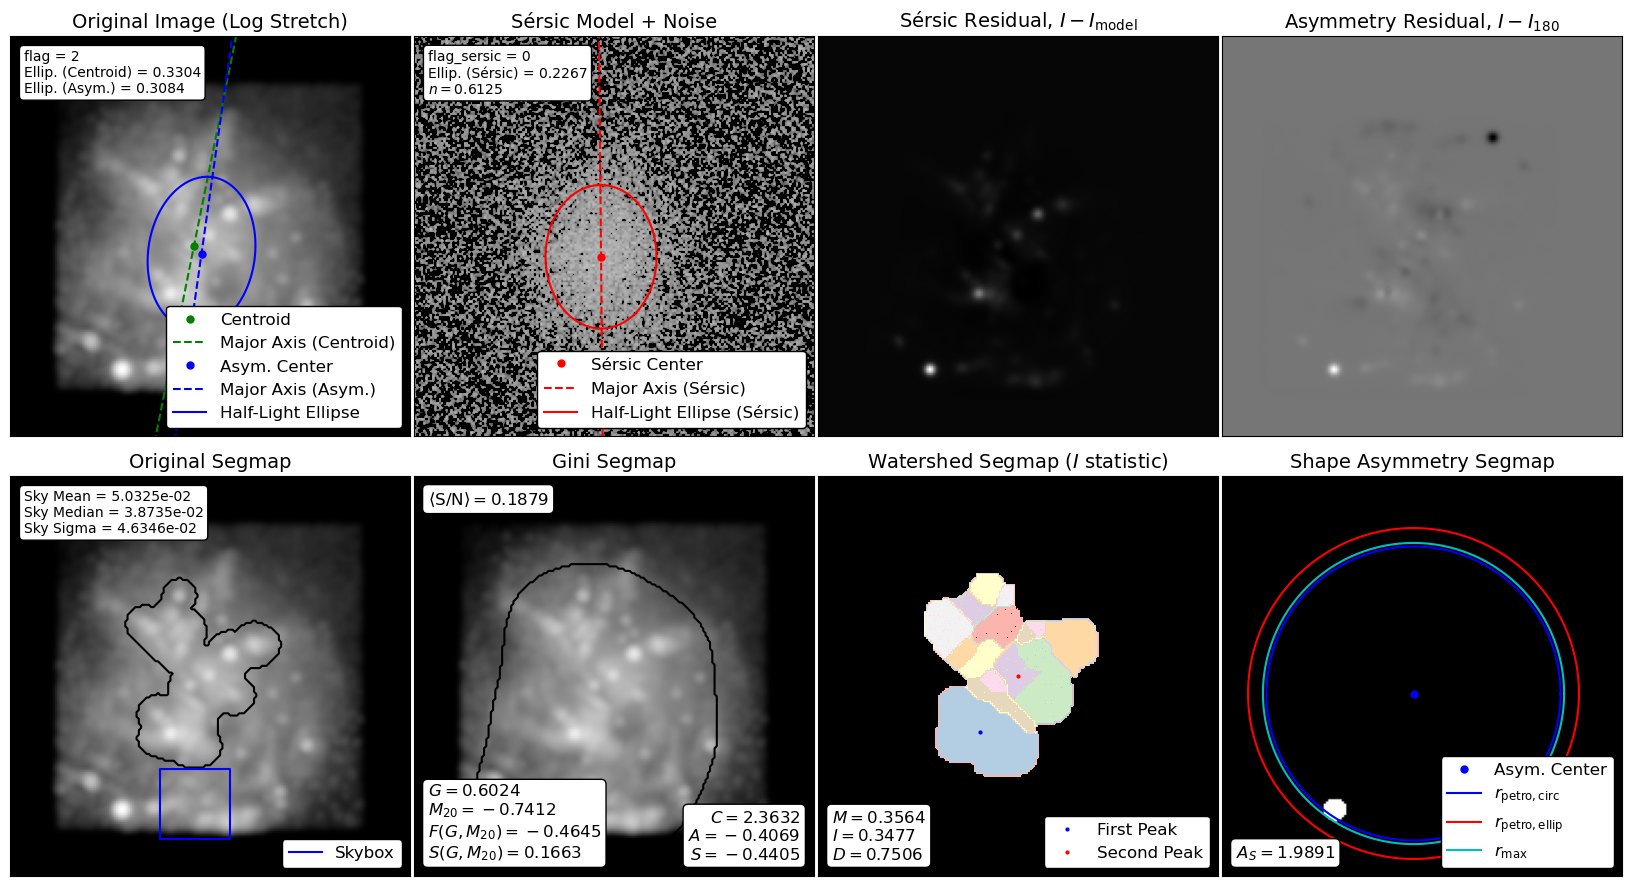

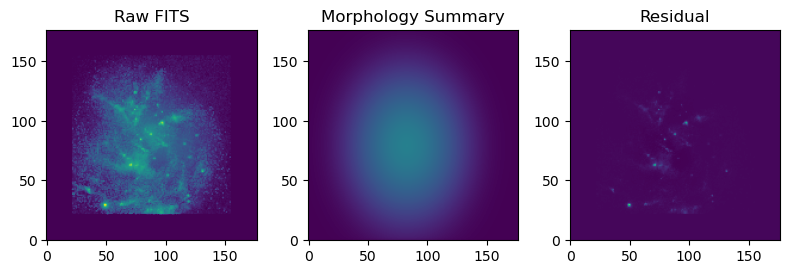

In [45]:
def statMain(filename, wave=0, rmBG=False, verb=False, verbf=False, plotted=[True, True], exstr=''):
    #reorder_fits(filename, wave, exstr=exstr)
    imageFITS = paramFinder(wave, filename)
    
    #def crop_dead_edges(image, threshold=1e-6):
    #   mask = image > threshold  # True for real signal
    #   rows = np.any(mask, axis=1)
    #   cols = np.any(mask, axis=0)
    #   cropped = image[np.ix_(rows, cols)]
    #   return cropped
    
    #imageFITS = crop_dead_edges(imageFITS)
    
    if rmBG:
        imageFITS, x = subtract_background(imageFITS)
    
    segm, morph, image_model = runStatMorph(imageFITS)
    
    for i in range(len(morph)):
        if verb:
            #print(f'For object {i}')
            printStatMorph(morph[i], verbf)
            print()
    
    if plotted[0]:
        plotMorph(morph[0])
    if plotted[1]:
        plotImage(imageFITS, image_model)
    
    #os.remove(f"fits/temp/{exstr}tempfits.fits")
    
    return morph, [image_model, imageFITS]

if __name__ == "__main__":
    plt.close('all')
    filename = 'fits/NH_201_3_i0.00_a0.00_nodust_i0.00_a0.00_broad_NIRCam_super_total.fits'
    filename = 'fits/NH_134_2_i0.00_a0.00_nodust_i0.00_a0.00_broad_NIRCam_super_total.fits'
    #reorder_fits(filename, 3)
    #imageFITS = paramFinder()
    #reorder_fits(filename, 3)
    frame, img = statMain(filename, wave=3, rmBG=False, verb=True, plotted=[True, True])
    #frame, img, imageFITS = statMain(filename, wave=3, rmBG=False, verb=False, plotted=[True, True])
    

In [ ]:
def galLibTestFunc(): #Import check for wrapper functions
    return 0